# Mouse 720762: awake vs isoflurane vs full recording (Naman)

Session `720762-20240221-v001.nwb` (awake → isoflurane). This notebook covers the mandatory deliverables
for each of the three windows (awake only, isoflurane only, full recording):

1. EEG motif detection (frontal ch13, somatosensory ch10)
2. LFP motif detection (deep prelimbic, PL5 on probeF)
3. Power spectra (EEG and LFP)
4. Spike raster of the PL5 units under the LFP channel
5. Statistics tools: permutation-calibrated relaxed motif detection, and an exact permutation test of
   motif differences between states

Every motif detection runs in three versions: **original** (getMotifs.m rules), **strict** (same rules,
each state cut into ~5-min chunks treated as sessions) and **relaxed** (same chunks, permutation p-value
with size normalization, half the chunks). The full write-up, with the reasoning behind each method,
is `report_mouse720762_2026-11-01.docx` in the output folder.

The analysis takes about 5 minutes. With `RUN_PIPELINE = False` this notebook only loads and shows the
saved outputs.

In [1]:
import json, subprocess, sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

REPO = Path.cwd().resolve().parents[2]  # this notebook lives in code/python/notebooks/
PY = REPO / "code" / "python"
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
OUT = REPO / "data" / "out" / "2026-11-01_mouse720762"
FIG = OUT / "figures"
RUN_PIPELINE = False

if RUN_PIPELINE:
    subprocess.run([sys.executable, "-m", "src.state_motifs", "--nwb", str(NWB), "--out", str(OUT)], cwd=PY, check=True)
    subprocess.run([sys.executable, "-m", "src.motif_calibration", "--out", str(OUT / "diagnostics")], cwd=PY, check=True)

R = json.loads((OUT / "results.json").read_text())
show = lambda name, width=1000: display(Image(filename=str(FIG / name), width=width))
print(R["description"])

isoflurane experiment with EEG and Neuropixels (electrical and visual)


## Session timeline and analysis windows

Electrical stimulation blocks are excluded (see figure 2 for why). Windows are defined from the recorded isoflurane level.

In [2]:
tl = R["timeline"]
pd.DataFrame({
    "window": list(tl["windows"]),
    "start (s)": [round(v[0]) for v in tl["windows"].values()],
    "end (s)": [round(v[1]) for v in tl["windows"].values()],
})

,window,start (s),end (s)
0,awake,17,3264
1,isoflurane,3442,7124
2,full,17,7124


stimulation-free stretches used: [(17, 747), (2428, 4643), (6324, 7124)]
electrical stimulation blocks: [('awake', 752, 2423), ('isoflurane', 4648, 6319)]


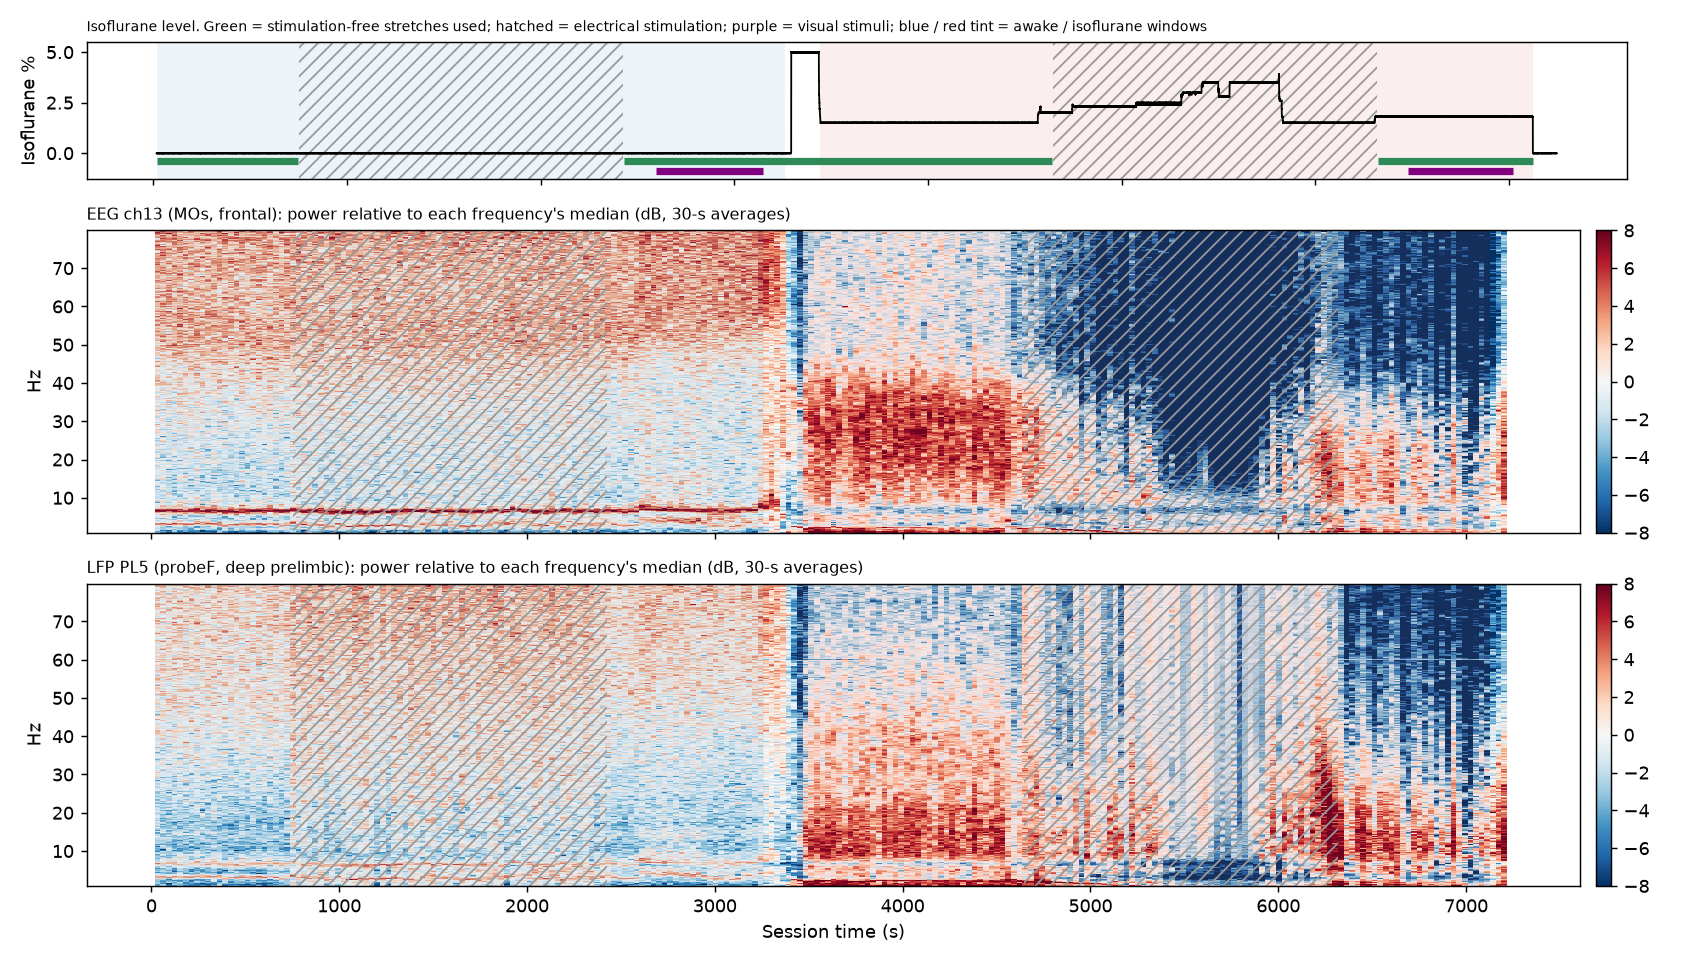

In [3]:
print("stimulation-free stretches used:", [(round(a), round(b)) for a, b in tl["stim_free_segments"]])
print("electrical stimulation blocks:", [(lab, round(a), round(b)) for lab, a, b in tl["electrical_blocks"]])
show("01_overview_timeline.png")

Why the stimulation blocks are excluded: the average response to each electrical pulse.

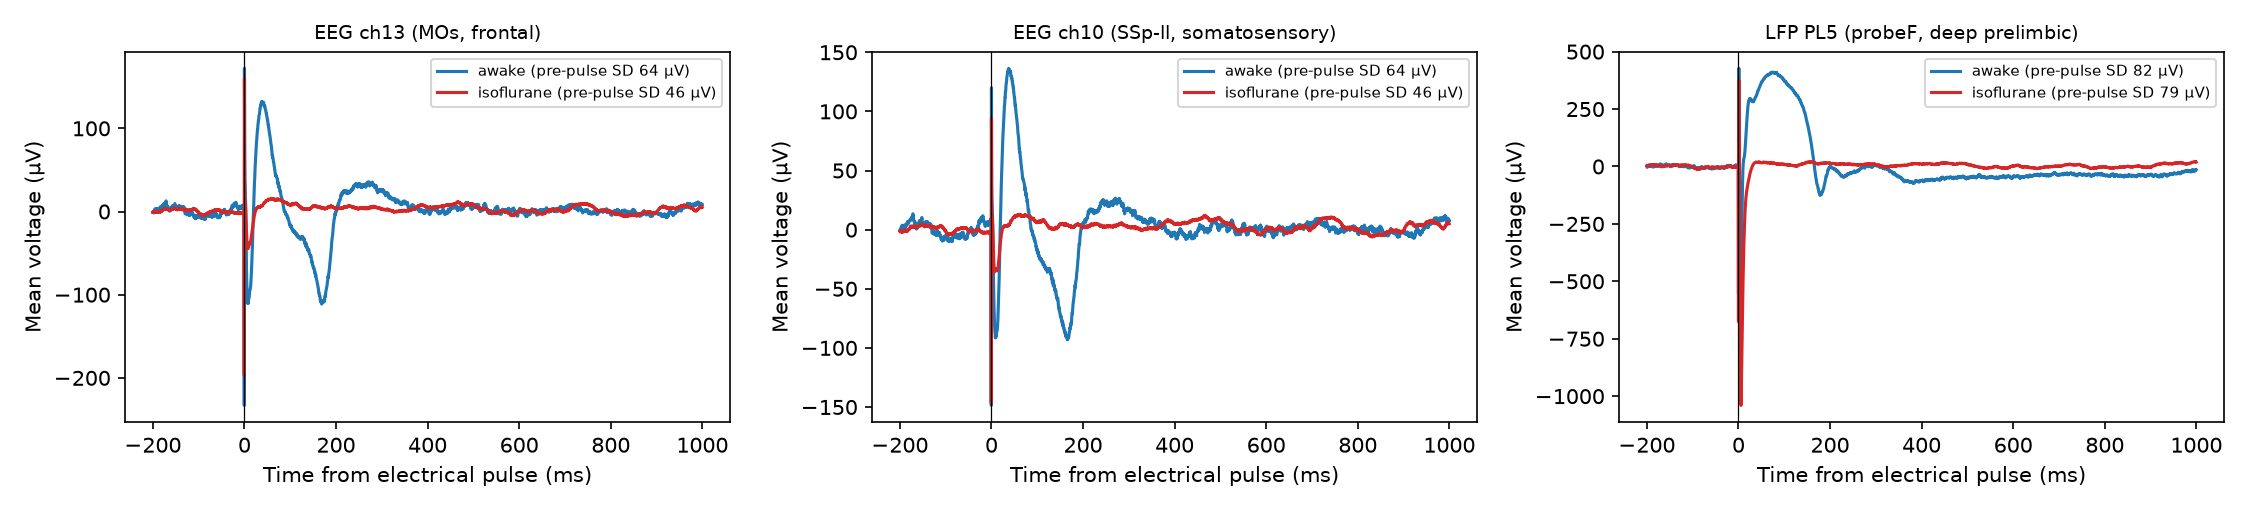

,awake,isoflurane
"EEG ch13 (MOs, frontal)",peak 172 µV vs pre-pulse SD 64 µV,peak 160 µV vs pre-pulse SD 46 µV
"EEG ch10 (SSp-ll, somatosensory)",peak 136 µV vs pre-pulse SD 64 µV,peak 95 µV vs pre-pulse SD 46 µV
"LFP PL5 (probeF, deep prelimbic)",peak 787 µV vs pre-pulse SD 82 µV,peak 1040 µV vs pre-pulse SD 79 µV


In [4]:
show("02_stimulation_response.png")
pd.DataFrame({sig: {st: f"peak {v['peak_abs_uv_0_500ms']:.0f} µV vs pre-pulse SD {v['pre_sd_uv']:.0f} µV"
                    for st, v in d.items()} for sig, d in R["stim_response"].items()}).T

## Deliverable 3: power spectra (awake, isoflurane, full)

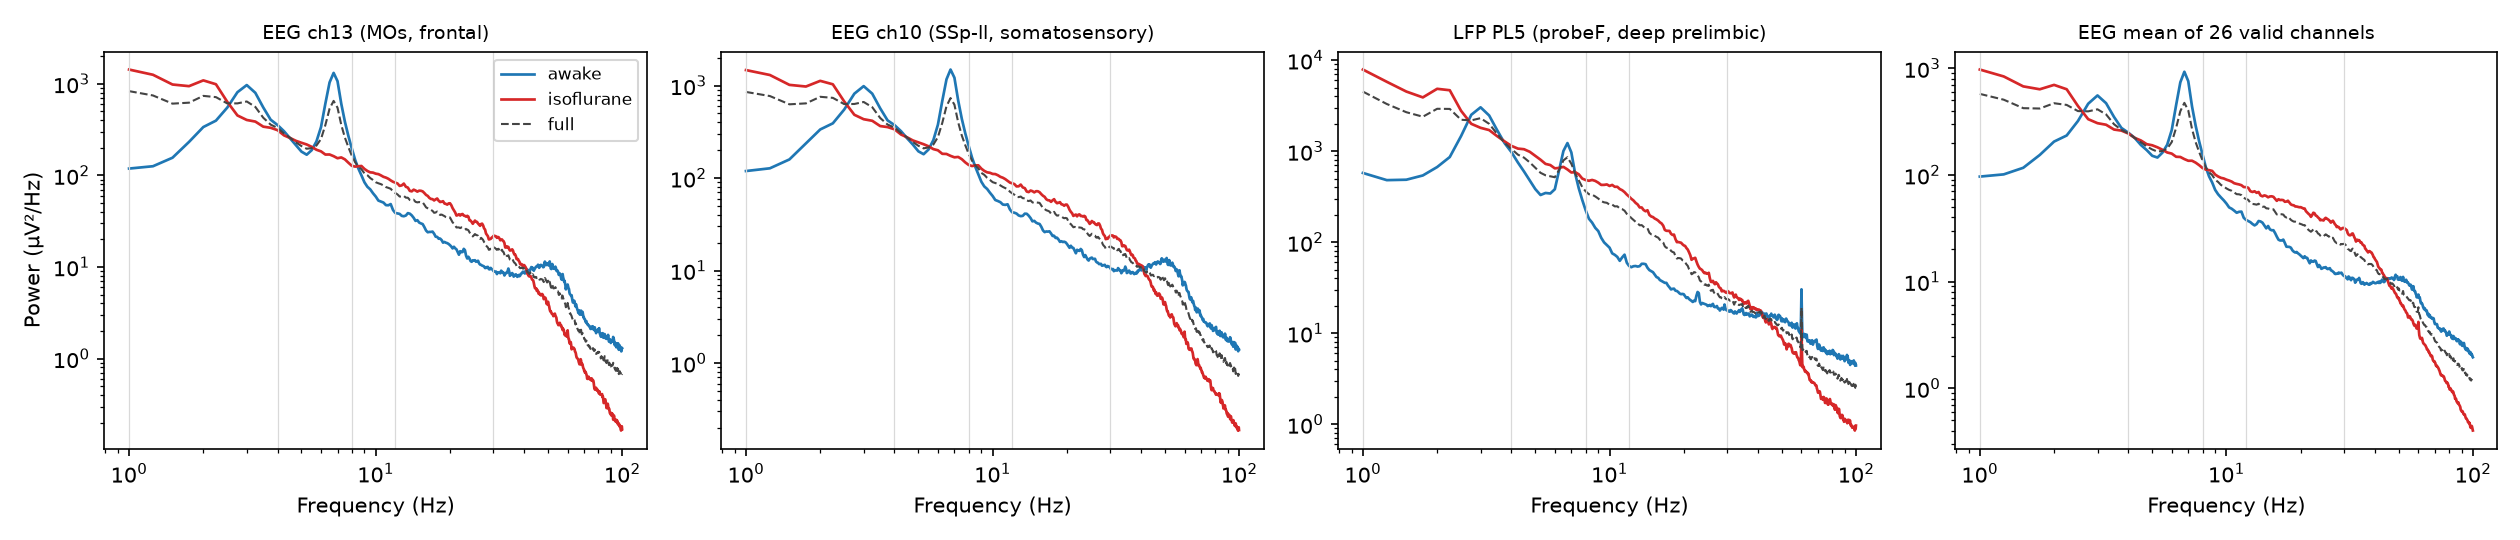

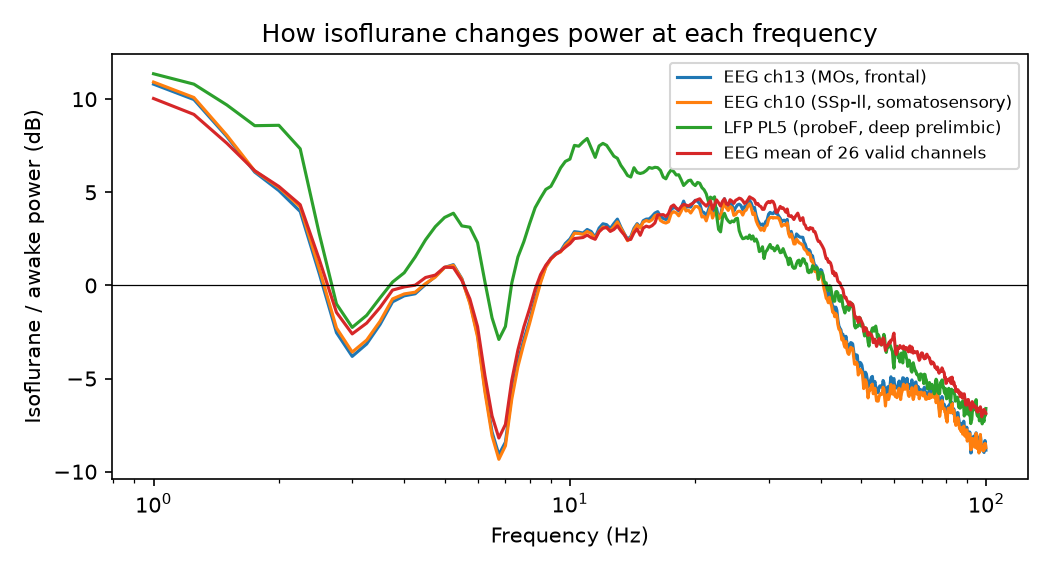

,"1-4 Hz (dB, iso vs awake)","4-8 Hz (dB, iso vs awake)","8-12 Hz (dB, iso vs awake)","12-30 Hz (dB, iso vs awake)","30-80 Hz (dB, iso vs awake)"
"EEG ch13 (MOs, frontal)",2.3,-3.7,1.3,3.7,-1.0
"EEG ch10 (SSp-ll, somatosensory)",2.4,-3.9,1.2,3.6,-1.3
"LFP PL5 (probeF, deep prelimbic)",4.3,1.0,5.9,5.4,-1.0
EEG mean of 26 valid channels,2.8,-3.1,1.4,3.8,0.4


In [5]:
show("03_power_spectra.png")
show("04_power_ratio_iso_vs_awake.png", 700)
pd.DataFrame(R["spectra_band_power_db_change"]).T.round(1).rename(columns=lambda c: c + " Hz (dB, iso vs awake)")

## Deliverable 4: PL5 spike raster (awake, induction, isoflurane, full recording)

63 of 234 PL5 units pass the quality filters {'isi_violations': 0.5, 'amplitude_cutoff': 0.1, 'presence_ratio': 0.9}


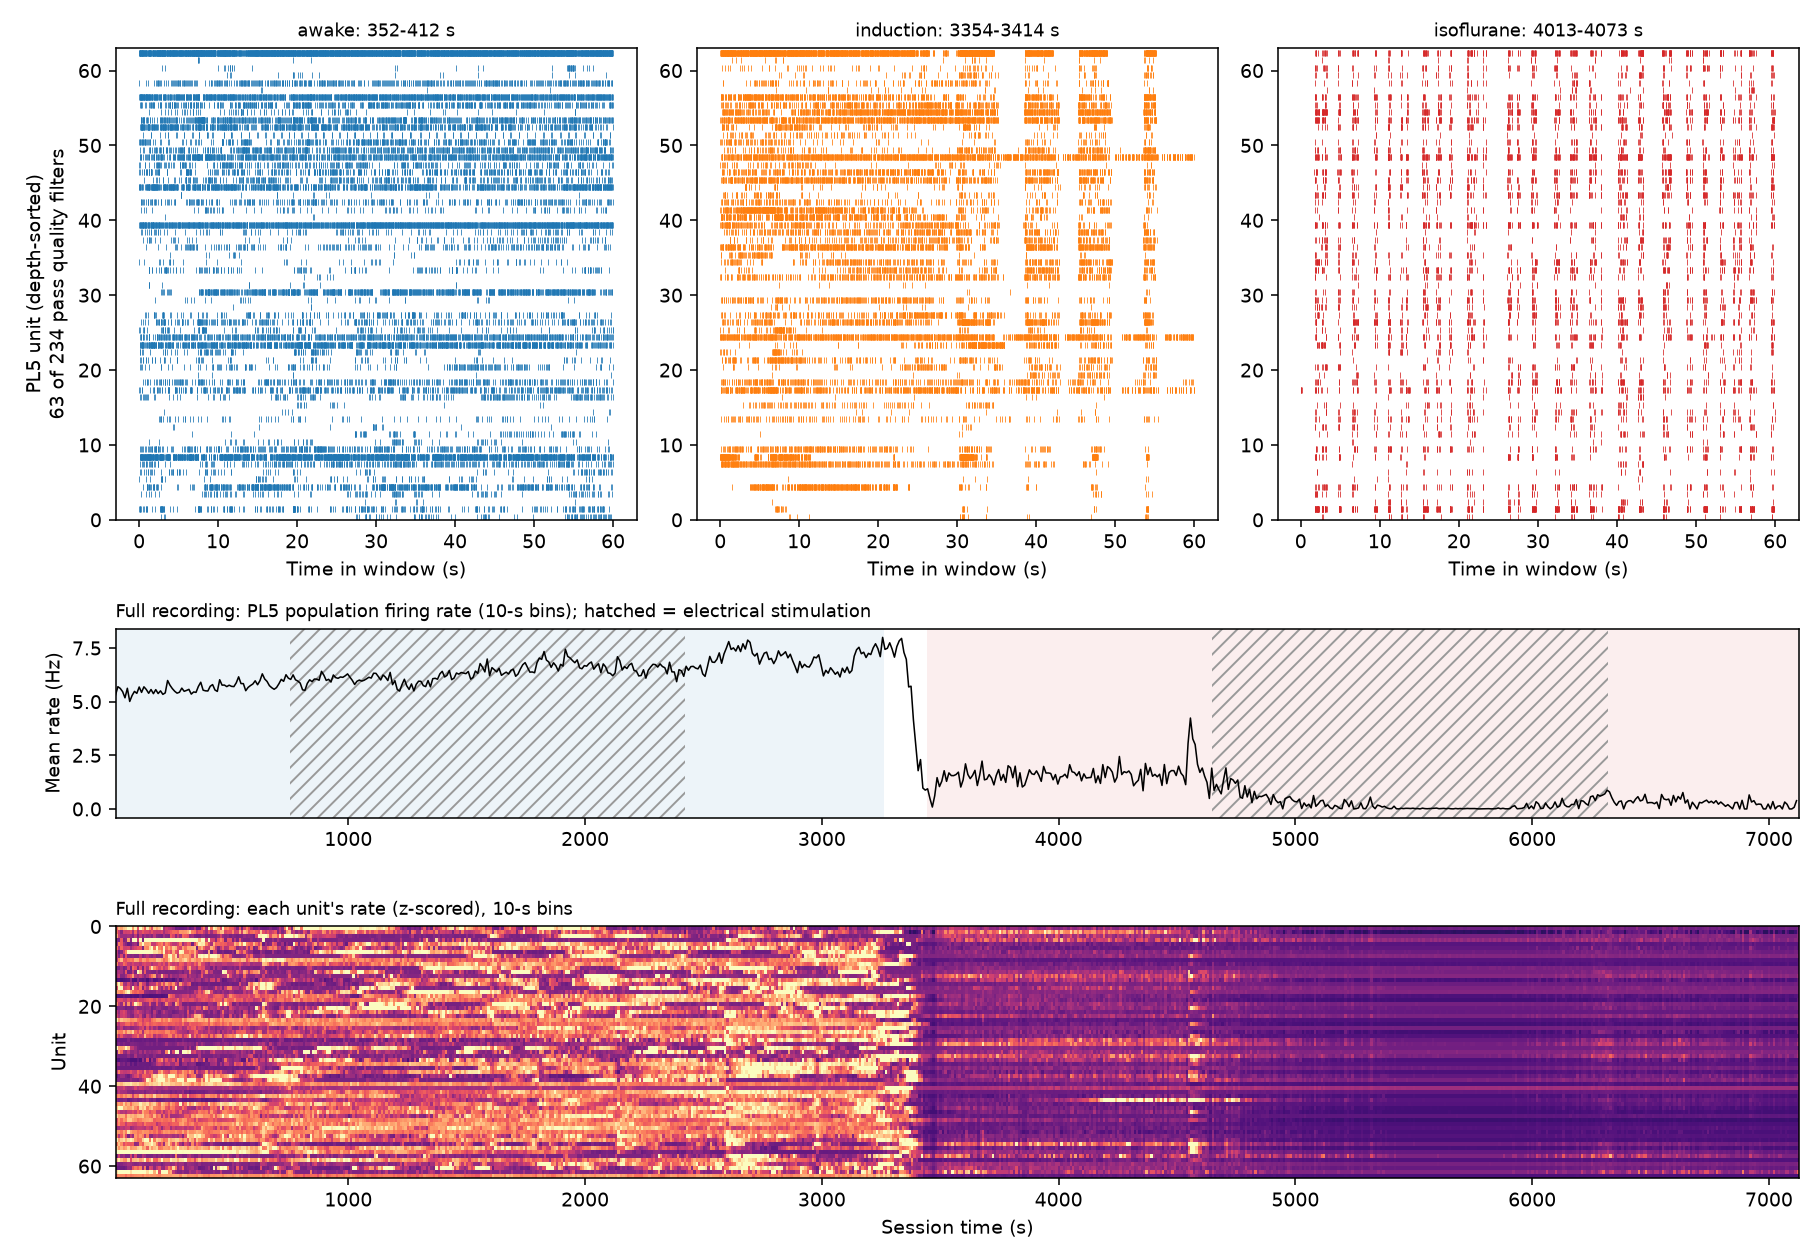

In [6]:
u = R["pl5_units"]
print(f"{u['n_good']} of {u['n_total']} PL5 units pass the quality filters {u['criteria']}")
show("05_PL5_raster.png")

## Deliverables 1 and 2: EEG and LFP motif detection (three windows × three versions)

In [7]:
runs = pd.DataFrame(R["motif_runs"])
table = runs.assign(min_p=runs.motif_support.apply(lambda s: [round(x["min_p"], 3) for x in s]),
                    broadband_like=runs.broadband_like)
table.pivot_table(index=["signal", "window"], columns="version", values="n_motifs", aggfunc="first")

version             original  relaxed  strict
signal  window                               
eeg10   awake              0        0       0
        full               0        0       0
        isoflurane         0        1       0
eeg13   awake              0        0       0
        full               0        1       0
        isoflurane         0        1       0
lfp_PL5 awake              1        1       1
        full               0        1       0
        isoflurane         0        1       0

In [8]:
table[table.n_motifs > 0][["signal", "window", "version", "n_sessions", "n_timepoints", "n_motifs",
                           "min_p", "broadband_like"]]

,signal,window,version,n_sessions,n_timepoints,n_motifs,min_p,broadband_like
5,eeg13,isoflurane,relaxed,5,1191,1,[0.01],[False]
8,eeg13,full,relaxed,11,3150,1,[0.01],[False]
14,eeg10,isoflurane,relaxed,5,1183,1,[0.01],[False]
18,lfp_PL5,awake,original,1,1531,1,[0.048],[False]
19,lfp_PL5,awake,strict,4,1531,1,[0.048],[False]
20,lfp_PL5,awake,relaxed,4,1531,1,[0.01],[False]
23,lfp_PL5,isoflurane,relaxed,5,983,1,[0.01],[False]
26,lfp_PL5,full,relaxed,11,3112,1,[0.01],[False]


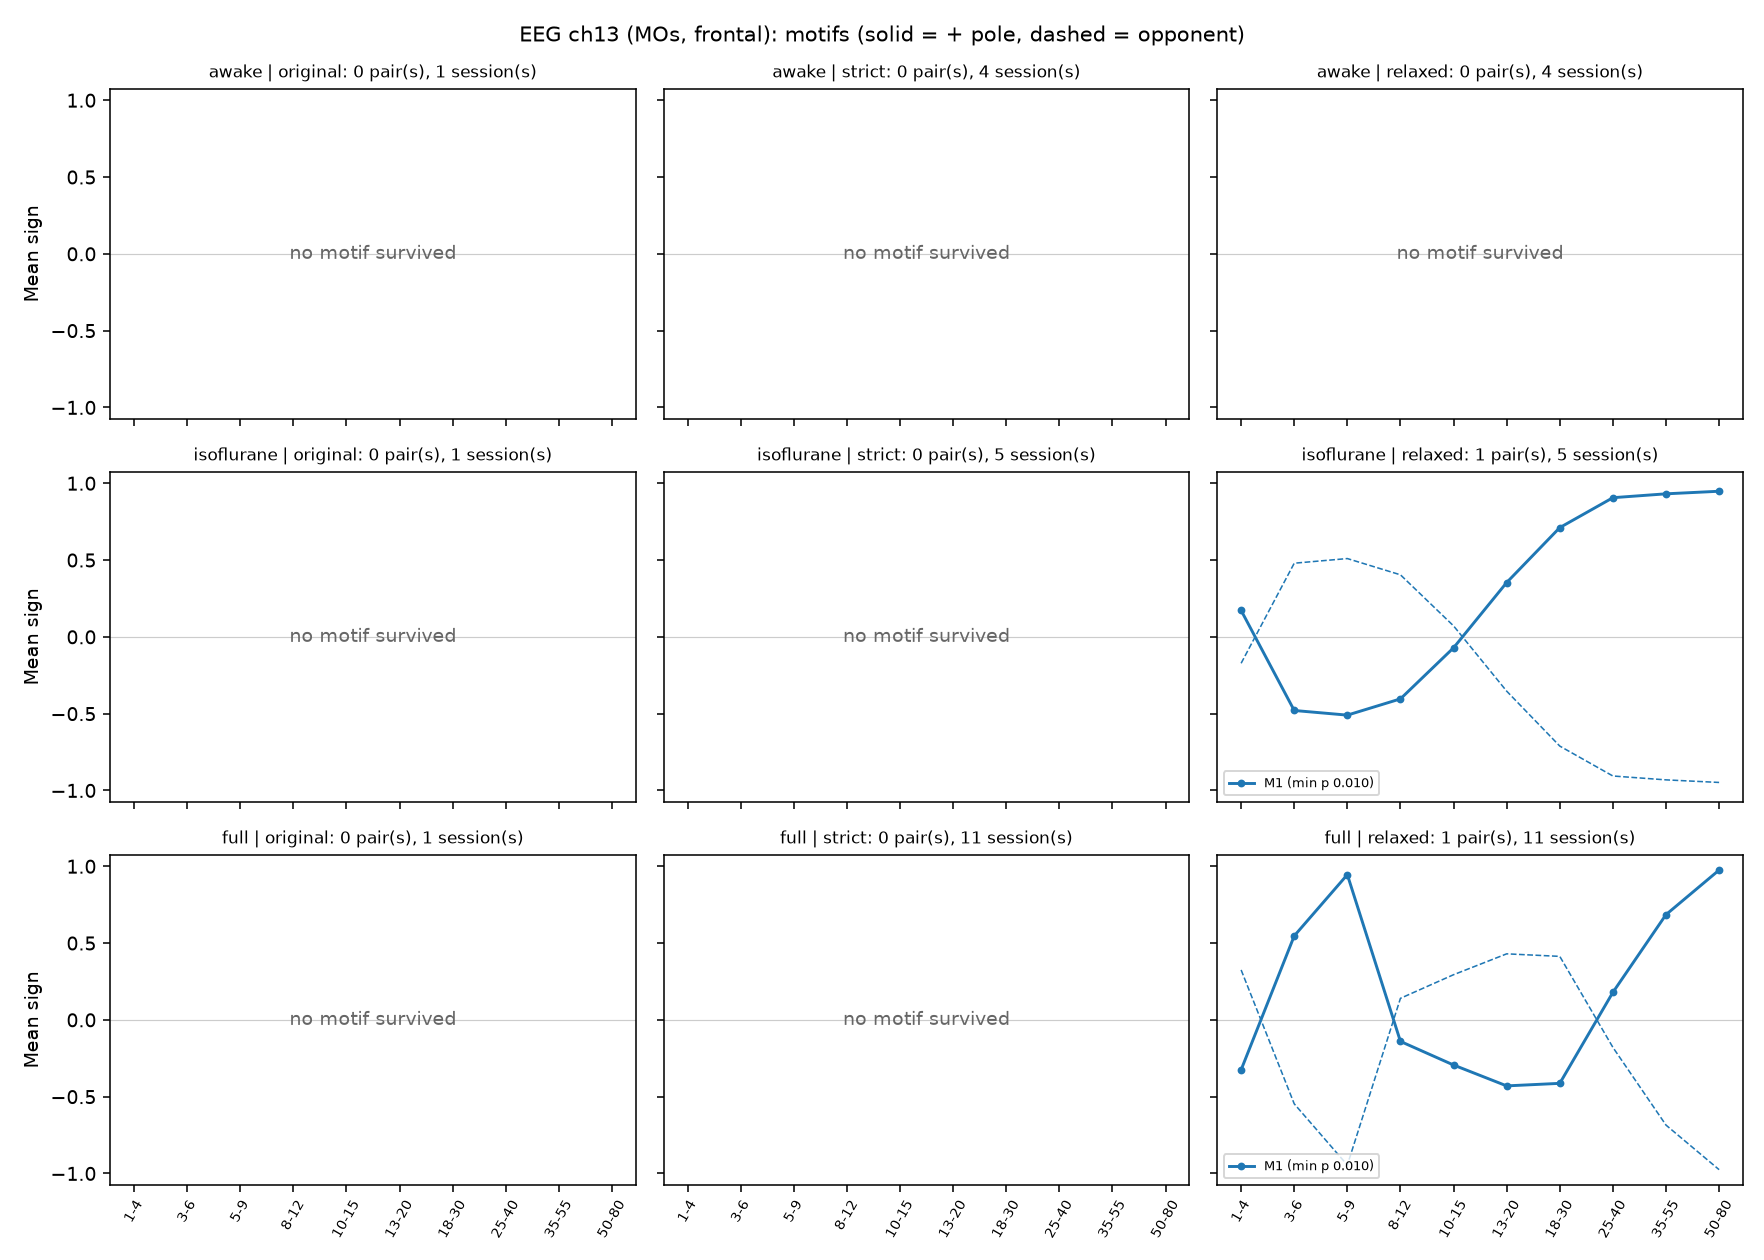

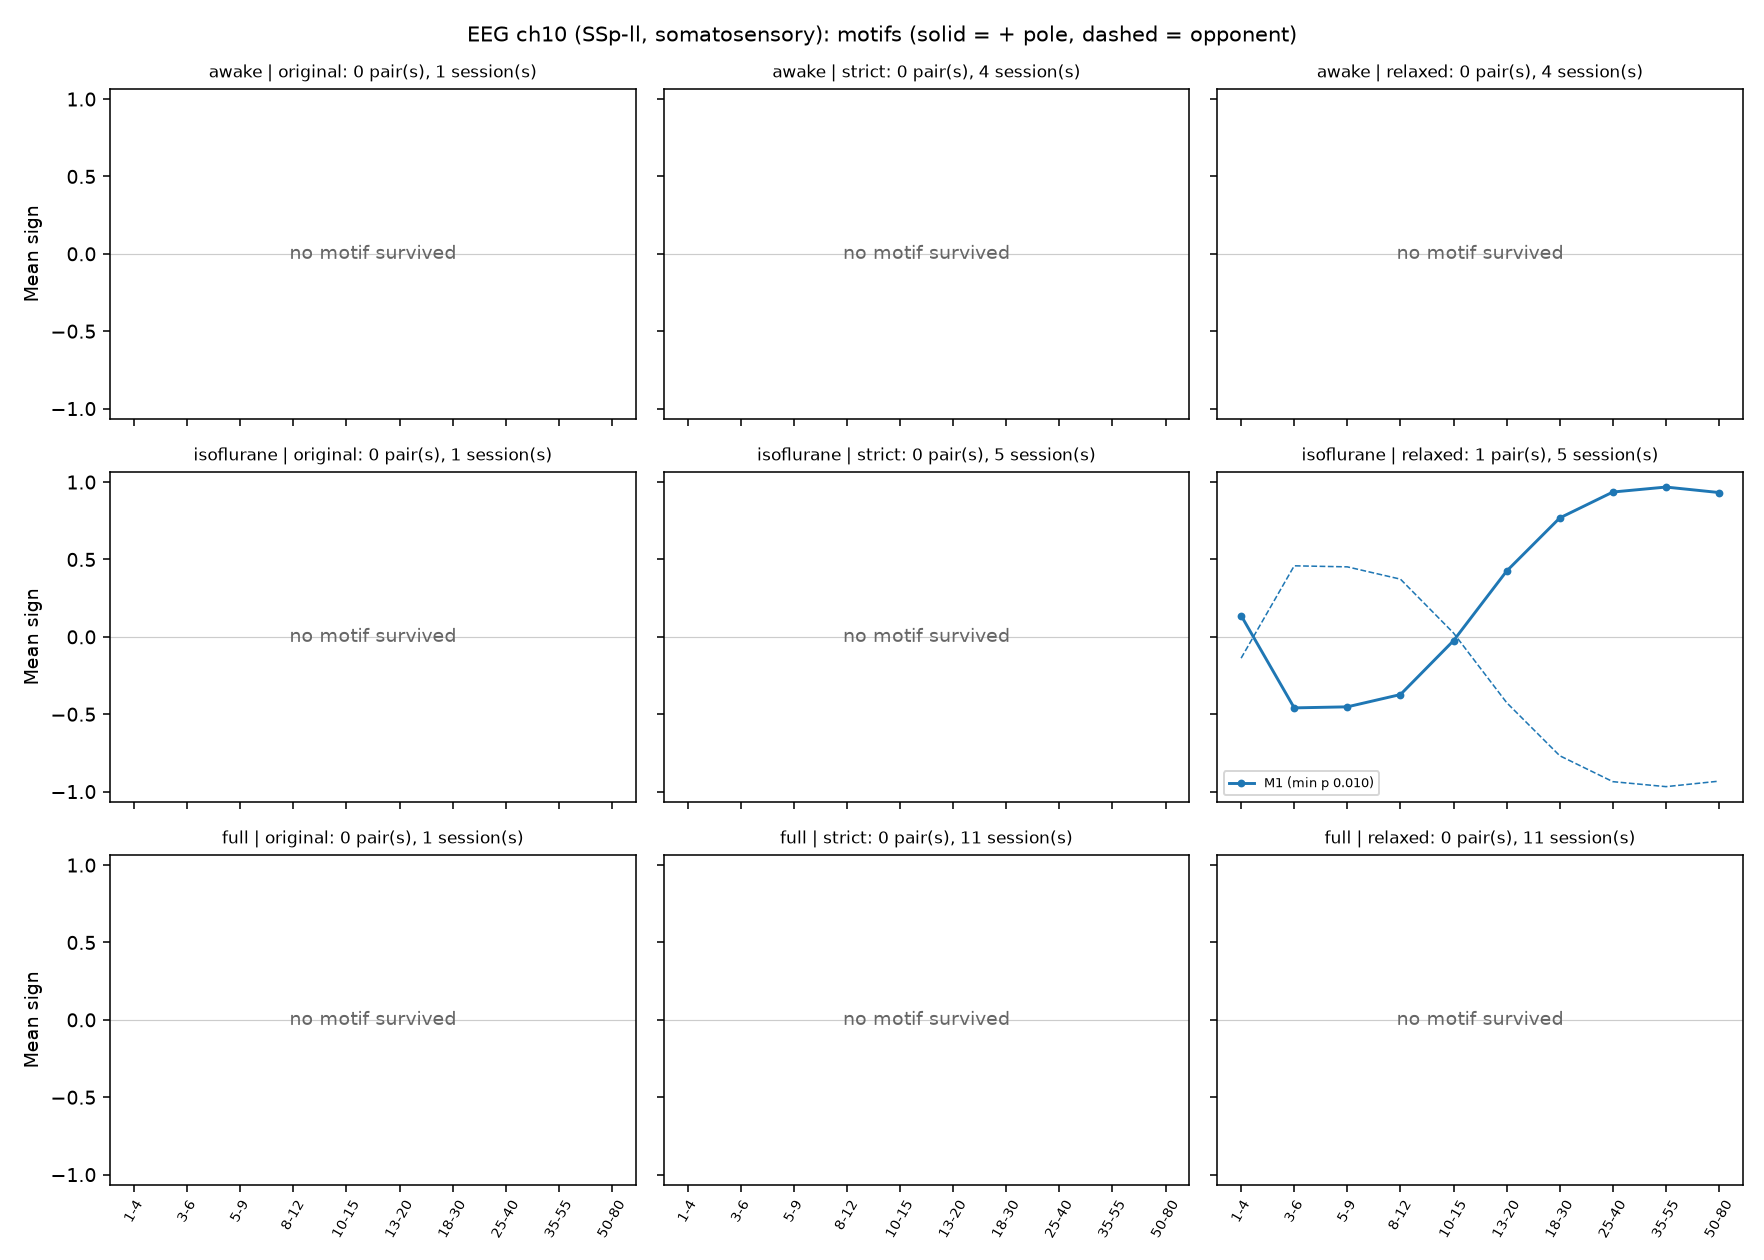

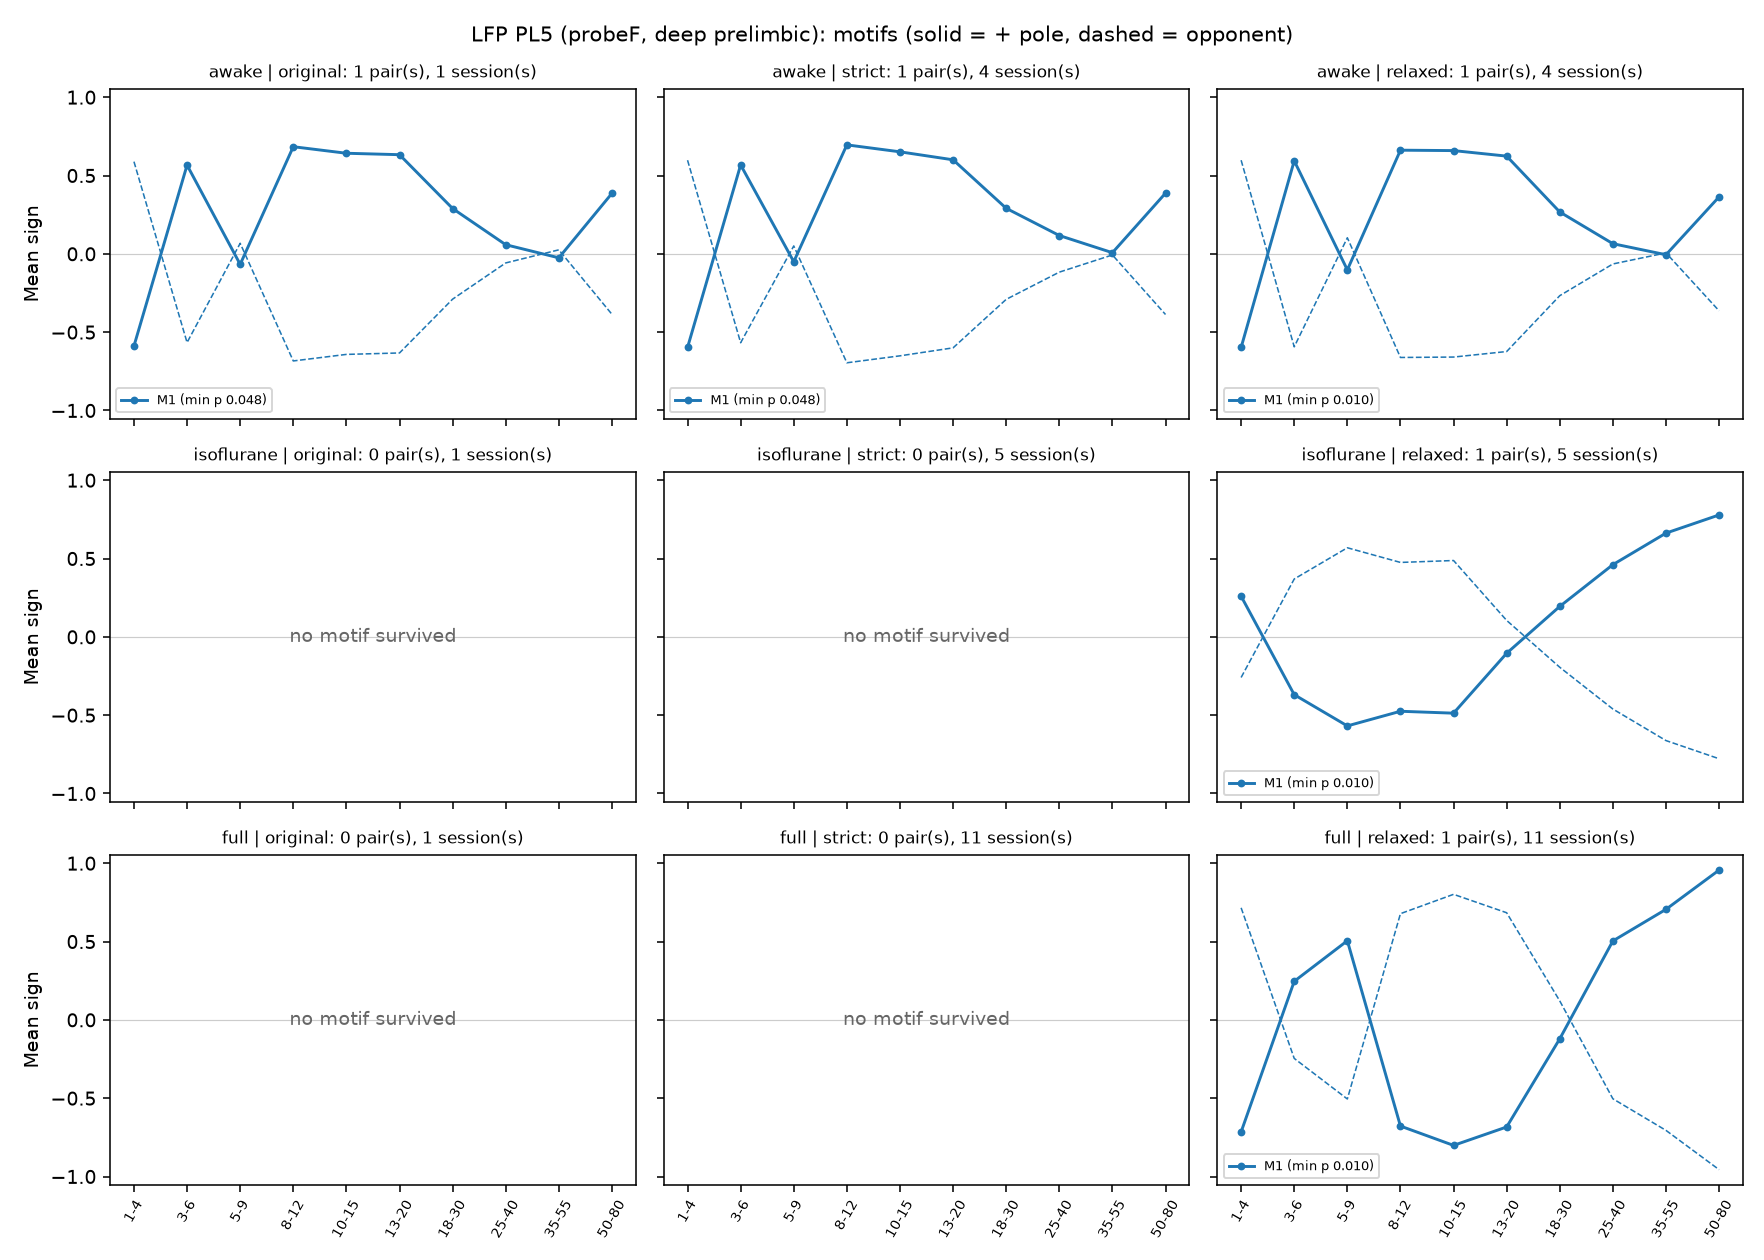

In [9]:
for key in ("eeg13", "eeg10", "lfp_PL5"):
    show(f"06_motifs_{key}.png")

### Guardrails

The relaxed version is checked on real data with every band shuffled independently (destroys any cross-band pattern) and on synthetic motif-free data.

In [10]:
g = pd.DataFrame(R["guardrail"])
print("motifs found on band-shuffled real data:", int(g.n_motifs.sum()), "in", len(g), "runs")
cal = OUT / "diagnostics" / "calibration.json"
pd.DataFrame(json.loads(cal.read_text())).pivot(index="config", columns="data", values="datasets_with_false_motif") if cal.exists() else "calibration not run yet"

motifs found on band-shuffled real data: 0 in 18 runs


data,broadband w=0.5,broadband w=1,broadband w=2,independent
config,,,,
relaxed: ... + PCA support 1 (rejected),18,20,19,3
relaxed: ... + size normalization (used),16,20,19,0
relaxed: p-value + half the chunks,11,20,17,0
strict (getMotifs.m rules),10,19,17,1


## Deliverable 5: statistics

### Are motifs the same across states? (chunk bootstrap)

In [11]:
B = json.loads((OUT / "bootstrap.json").read_text())
import numpy as np
pd.DataFrame([{"signal": r["signal"],
               "found awake": r["awake"]["detection_rate"], "found iso": r["isoflurane"]["detection_rate"],
               "awake vs awake |r|": np.median(r["awake"]["within_abs_r"]) if r["awake"]["within_abs_r"] else None,
               "iso vs iso |r|": np.median(r["isoflurane"]["within_abs_r"]) if r["isoflurane"]["within_abs_r"] else None,
               "awake vs iso |r|": np.median(r["across_abs_r"]) if r["across_abs_r"] else None} for r in B["results"]]).round(2)

,signal,found awake,found iso,awake vs awake |r|,iso vs iso |r|,awake vs iso |r|
0,eeg13,0.28,0.68,0.98,0.99,0.34
1,eeg10,0.45,0.52,0.98,0.99,0.36
2,lfp_PL5,0.88,0.92,0.98,0.96,0.37


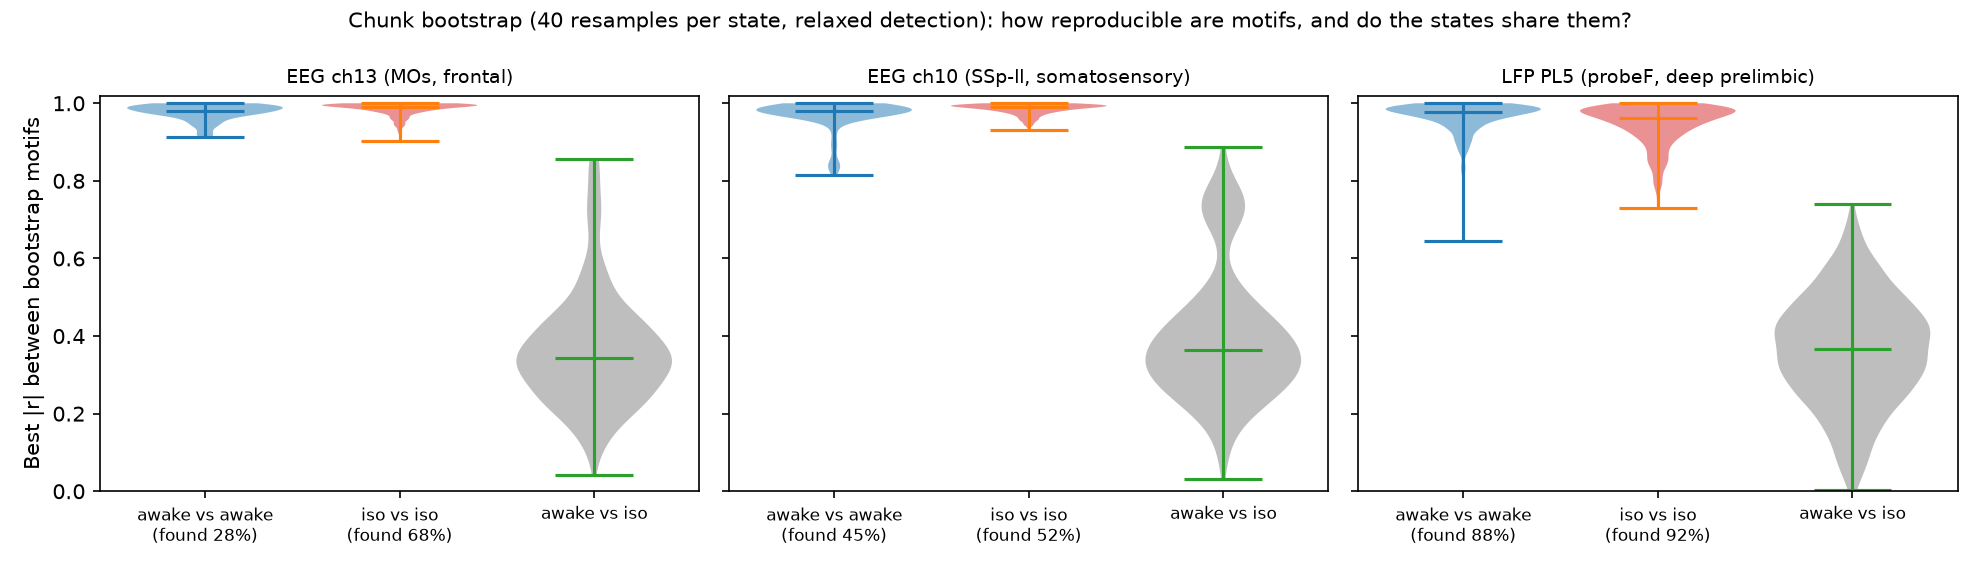

In [12]:
show("10_bootstrap_stability.png")

### Exact permutation test over 5-minute chunks (full-recording motifs)

,signal,reference version,motif,n_awake_chunks,n_iso_chunks,n_permutations,balance_diff,balance_p,shape_within,shape_between,shape_gap,shape_p
0,eeg13,relaxed,1,4,5,126,1.991,0.008,0.337,0.330,-0.007,0.405
1,lfp_PL5,relaxed,1,4,5,126,1.978,0.008,0.204,0.268,0.064,0.111


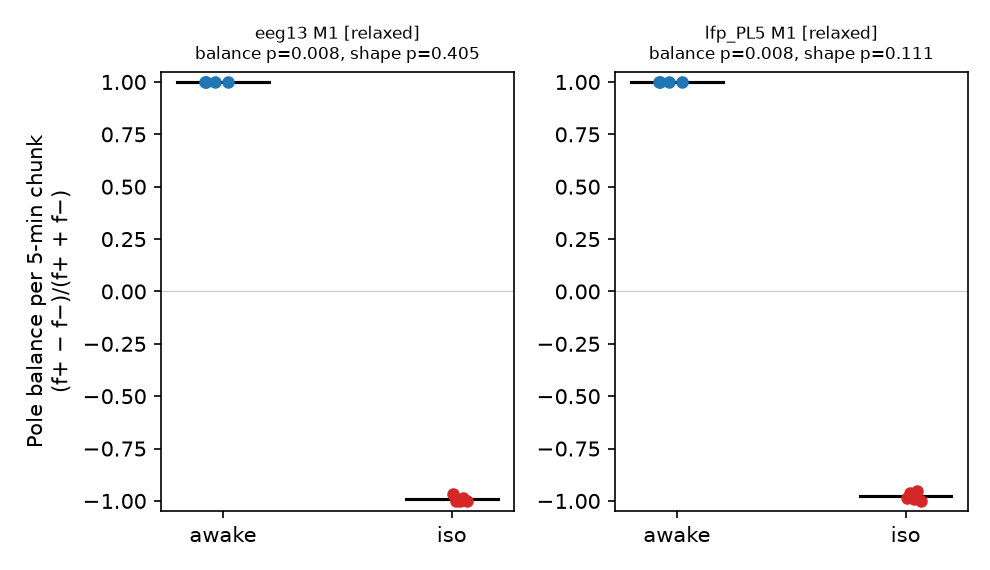

In [13]:
rows = [{"signal": sig, "reference version": d["version"], **{k: v for k, v in t.items()
          if not k.startswith("balance_a") and k != "balance_iso"}} for sig, d in R["permutation_tests"].items()
        for t in d["tests"]]
display(pd.DataFrame(rows).round(3))
if (FIG / "08_permutation_test.png").exists():
    show("08_permutation_test.png", 800)

### Frontal EEG vs deep LFP, and do LFP motifs track spiking?

In [14]:
pd.DataFrame([{"window": e["window"], "eeg": e["eeg"], "shape |r| with LFP motif": e["shape_abs_r"][0][0],
               **{f"pole co-occurrence r ({k})": v["r"][0][0] for k, v in e["temporal"].items()}}
              for e in R["eeg_vs_lfp"]]).round(2)

,window,eeg,shape |r| with LFP motif,pole co-occurrence r (full),pole co-occurrence r (isoflurane),pole co-occurrence r (awake)
0,isoflurane,eeg13,0.93,0.68,0.68,NaN
1,isoflurane,eeg10,0.91,0.68,0.68,NaN
2,full,eeg13,0.88,0.95,0.73,NaN


,state,motif,rate_plus_z,rate_minus_z,diff,p,n_plus,n_minus,mean_rate_hz,version
0,awake,1,0.566,-0.373,0.939,0.001,611,919,6.359,strict
1,isoflurane,1,0.321,-0.319,0.641,0.072,598,391,1.070,relaxed


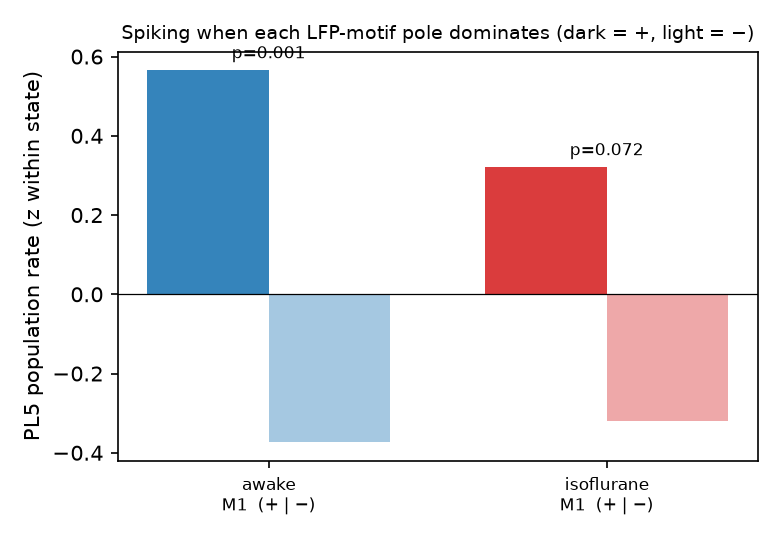

In [15]:
display(pd.DataFrame(R["spikes_by_lfp_pole"]).round(3))
if (FIG / "09_spikes_by_LFP_pole.png").exists():
    show("09_spikes_by_LFP_pole.png", 700)